In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('Employee_Data.csv')

pd.options.display.max_rows=500
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [18]:
# Binary: Attrition, Gender, Over18, OverTime
df['Attrition' ] = df['Attrition' ].apply(lambda x: 1 if x == 'Yes' else 0)
df['Gender' ] = df ['Gender' ]. apply(lambda x: 1 if x == 'Male' else 0)
df['Over18'] = df['Over18'].apply(lambda x: 1 if x == 'Y' else 0)
df['OverTime' ] = df ['OverTime' ].apply(lambda x: 1 if x == 'Yes' else 0)
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,0,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,0,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,0,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,0,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [19]:
# One-Hot Encoding: Business Travel, Department, EducationField, JobRole, Marital Status
df=df.join(pd.get_dummies(df['BusinessTravel'])).drop('BusinessTravel',axis=1) 
df=df.join(pd.get_dummies(df['Department'],prefix='Department')).drop('Department',axis=1) 
df=df.join(pd.get_dummies(df['EducationField'],prefix='Field')).drop('EducationField',axis=1) 
df=df.join(pd.get_dummies(df['JobRole'],prefix='Role')).drop('JobRole',axis=1) 
df=df.join(pd.get_dummies(df['MaritalStatus'],prefix='Status')).drop('MaritalStatus',axis=1)


In [20]:

df=df.drop(['EmployeeCount','Over18','StandardHours'],axis=1)
df

,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,...,Role_Laboratory Technician,Role_Manager,Role_Manufacturing Director,Role_Research Director,Role_Research Scientist,Role_Sales Executive,Role_Sales Representative,Status_Divorced,Status_Married,Status_Single
0,41,1,1102,1,2,1,2,0,94,3,...,False,False,False,False,False,True,False,False,False,True
1,49,0,279,8,1,2,3,1,61,2,...,False,False,False,False,True,False,False,False,True,False
2,37,1,1373,2,2,4,4,1,92,2,...,True,False,False,False,False,False,False,False,False,True
3,33,0,1392,3,4,5,4,0,56,3,...,False,False,False,False,True,False,False,False,True,False
4,27,0,591,2,1,7,1,1,40,3,...,True,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,0,884,23,2,2061,3,1,41,4,...,True,False,False,False,False,False,False,False,True,False
1466,39,0,613,6,1,2062,4,1,42,2,...,False,False,False,False,False,False,False,False,True,False
1467,27,0,155,4,3,2064,2,1,87,4,...,False,False,True,False,False,False,False,False,True,False
1468,49,0,1023,2,3,2065,4,1,63,2,...,False,False,False,False,False,True,False,False,True,False


In [21]:
df = df.applymap(lambda x: 1 if x is True else 0 if x is False else x)


C:\Users\hp\AppData\Local\Temp\ipykernel_2752\503258950.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: 1 if x is True else 0 if x is False else x)


Model Training


In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X, y = df.drop('Attrition', axis=1), df['Attrition']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = RandomForestClassifier(n_jobs=-1)
model.fit(X_train, y_train)
print("Model training succeded")

Model training succeded


Checking the Accuracy

In [24]:
model.score(X_test,y_test)

0.8469387755102041

Checking the feture importances

In [26]:
sorted(zip(model.feature_names_in_,model.feature_importances_),key=lambda x:x[1],reverse=True)

[('MonthlyIncome', np.float64(0.06437875147647686)),
 ('Age', np.float64(0.05835946854498331)),
 ('OverTime', np.float64(0.05146453887593941)),
 ('DailyRate', np.float64(0.05135529930805792)),
 ('MonthlyRate', np.float64(0.04883289788185224)),
 ('HourlyRate', np.float64(0.04872644863850693)),
 ('EmployeeNumber', np.float64(0.04783311313470198)),
 ('TotalWorkingYears', np.float64(0.045081021478596495)),
 ('YearsAtCompany', np.float64(0.04124837906268876)),
 ('DistanceFromHome', np.float64(0.03845638513771062)),
 ('PercentSalaryHike', np.float64(0.03227284433272388)),
 ('YearsWithCurrManager', np.float64(0.031918440066336116)),
 ('NumCompaniesWorked', np.float64(0.03174896469748126)),
 ('JobSatisfaction', np.float64(0.028030504042038922)),
 ('EnvironmentSatisfaction', np.float64(0.02615576666000625)),
 ('StockOptionLevel', np.float64(0.02544111857841793)),
 ('YearsInCurrentRole', np.float64(0.02486667719121276)),
 ('TrainingTimesLastYear', np.float64(0.02431498082548626)),
 ('YearsSinceL

In [27]:
sorted_importances=dict(sorted(zip(model.feature_names_in_,model.feature_importances_),key=lambda x:x[1] , reverse=True))

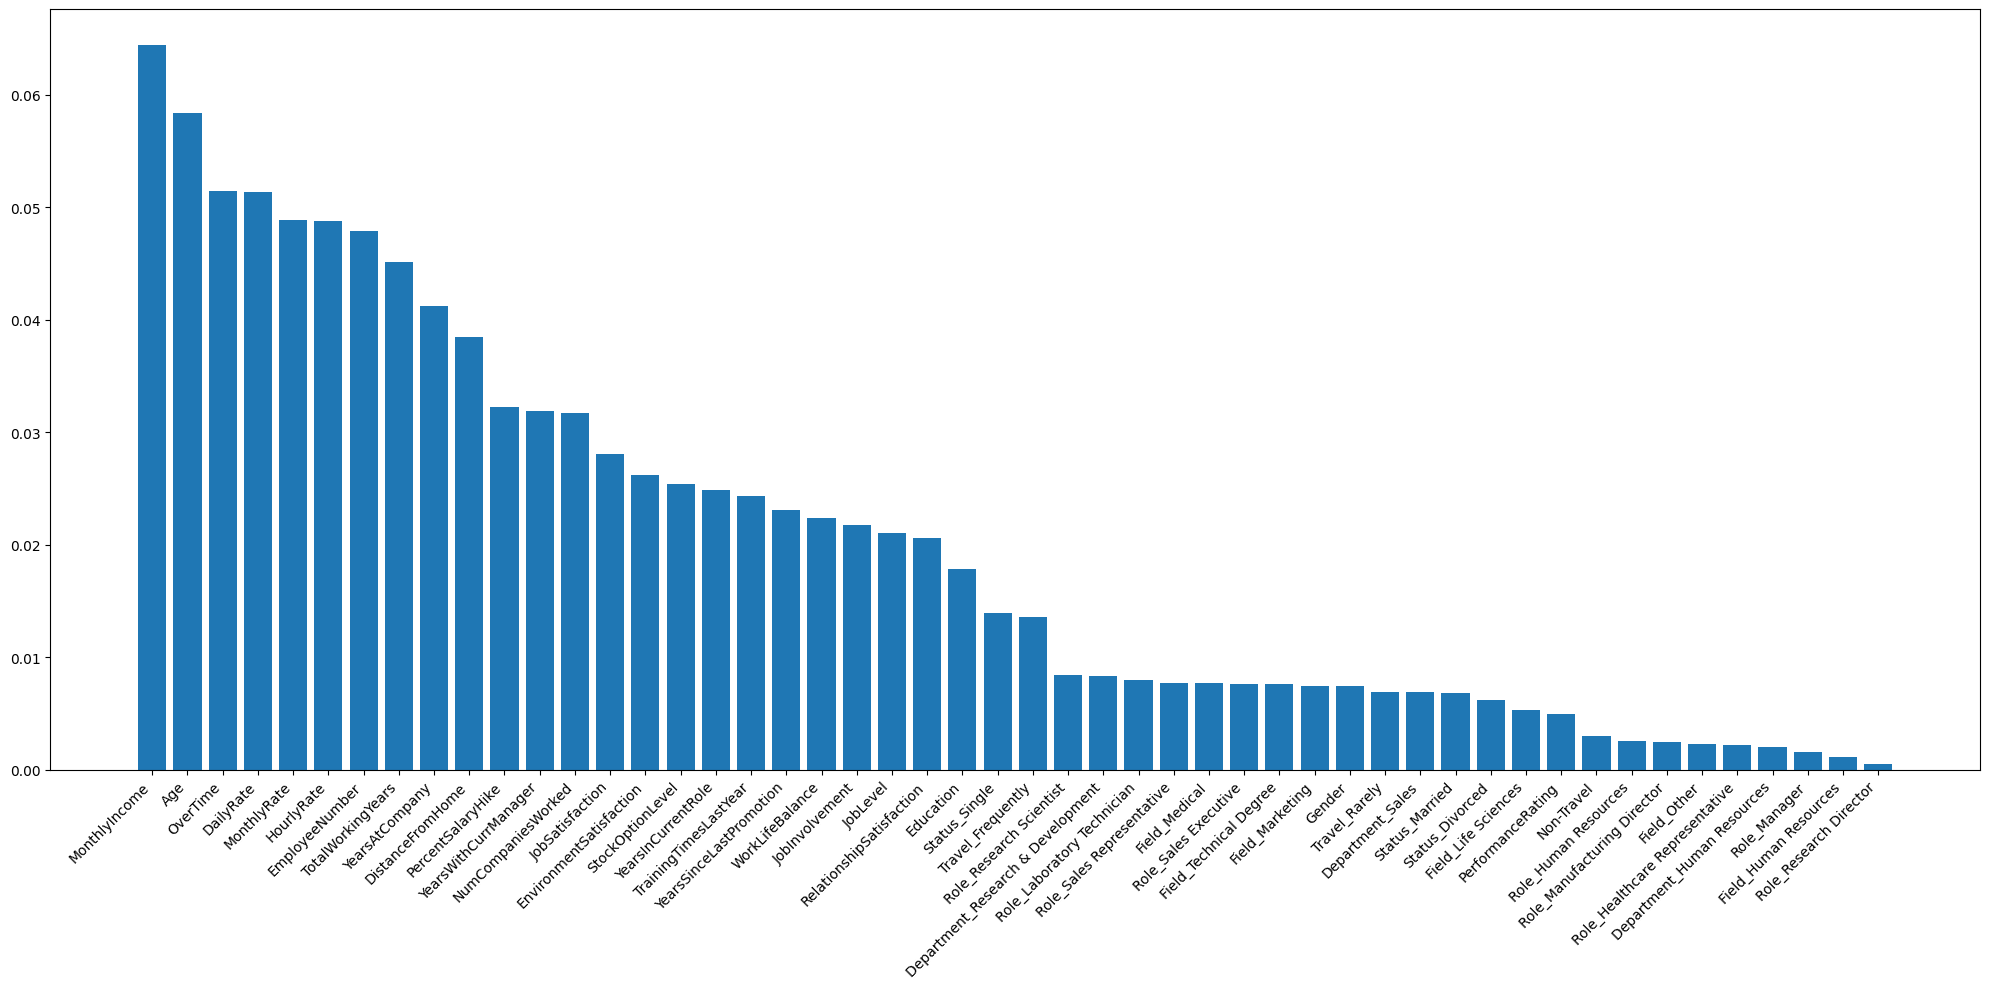

In [ ]:
plt.figure(figsize=(20,10))
plt.bar(sorted_importances.keys(),sorted_importances.values())
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [33]:
import pickle

# Save the trained model
with open('attrition_model.pkl', 'wb') as f:
    pickle.dump(model, f)

print("Model saved successfully!")


Model saved successfully!
